1.CARGAMOS Y EXPLORAMOS EL DATASET

In [15]:

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Cargar el dataset
df = pd.read_csv("amz_uk_price_prediction_dataset.csv")

# Exploración inicial
print(df.head())
print(df.shape)
print(df.info())
print(df.isnull().sum())


   uid        asin                                              title  stars  \
0    1  B09B96TG33  Echo Dot (5th generation, 2022 release) | Big ...    4.7   
1    2  B01HTH3C8S  Anker Soundcore mini, Super-Portable Bluetooth...    4.7   
2    3  B09B8YWXDF  Echo Dot (5th generation, 2022 release) | Big ...    4.7   
3    4  B09B8T5VGV  Echo Dot with clock (5th generation, 2022 rele...    4.7   
4    5  B09WX6QD65  Introducing Echo Pop | Full sound compact Wi-F...    4.6   

   reviews  price  isBestSeller  boughtInLastMonth        category  
0    15308  21.99         False                  0  Hi-Fi Speakers  
1    98099  23.99          True                  0  Hi-Fi Speakers  
2    15308  21.99         False                  0  Hi-Fi Speakers  
3     7205  31.99         False                  0  Hi-Fi Speakers  
4     1881  17.99         False                  0  Hi-Fi Speakers  
(2443651, 9)
<class 'pandas.DataFrame'>
RangeIndex: 2443651 entries, 0 to 2443650
Data columns (total 9 c

Part 1. Understanding Product Categories

1.1. Tabla de frecuencias
Utilizamos value_counts() para contar cuántos productos hay en cada categoría y head(5) para obtener las cinco más frecuentes.

In [16]:
# Tabla de frecuencias
category_counts = df["category"].value_counts()

print(category_counts.head(5))

category
Sports & Outdoors                         836265
Beauty                                     19312
Handmade Clothing, Shoes & Accessories     19229
Bath & Body                                19092
Birthday Gifts                             18978
Name: count, dtype: int64


1.2. Gráfico de barras

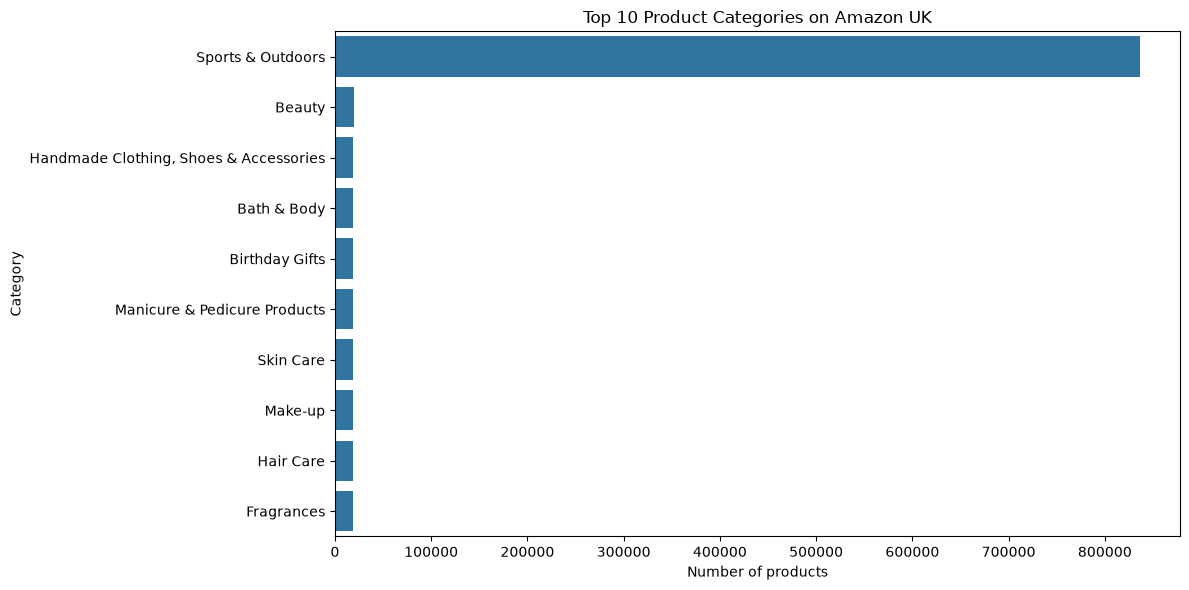

In [30]:
# Seleccionar las 10 categorías más frecuentes
top_categories = df["category"].value_counts().head(10)

plt.figure(figsize=(12, 6))

sns.barplot(x=top_categories.values,y=top_categories.index)

plt.title("Top 10 Product Categories on Amazon UK")
plt.xlabel("Number of products")
plt.ylabel("Category")
plt.tight_layout()
plt.show()

1.3. Gráfico circular (pie chart)

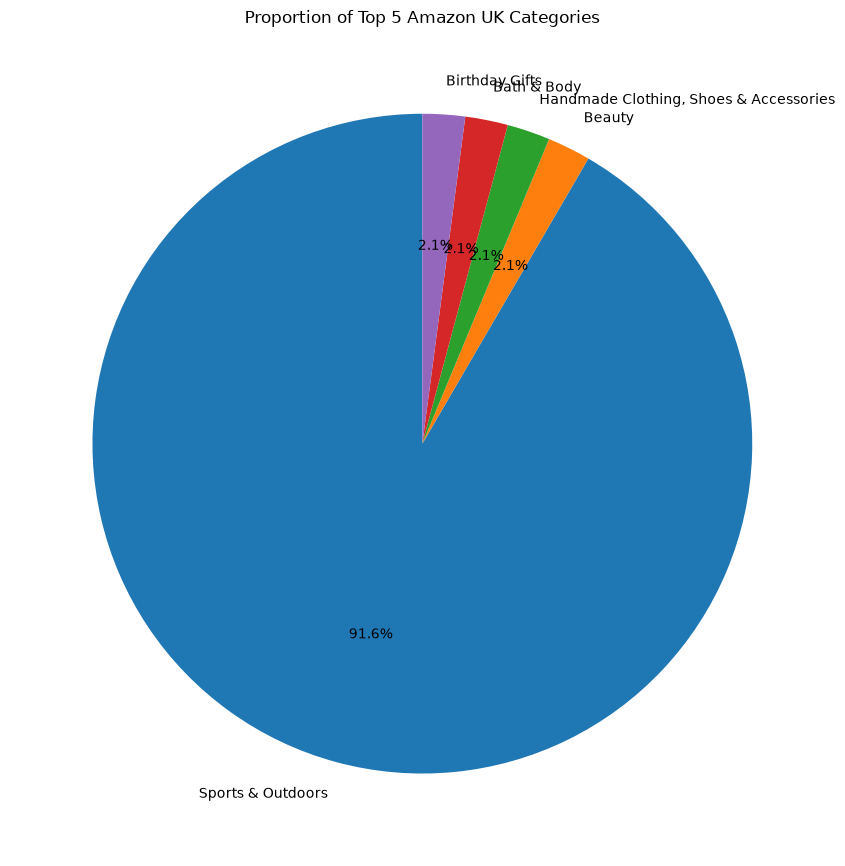

In [ ]:
top_5_categories = df["category"].value_counts().head(5)

plt.figure(figsize=(9, 9))
plt.pie(top_5_categories.values,labels=top_5_categories.index,autopct="%1.1f%%",startangle=90)

plt.title("Proportion of Top 5 Amazon UK Categories")
plt.tight_layout()
plt.show()

Part 2. Delving into Product Pricing

2.1. Medidas de tendencia central
Calcularemos la media, mediana y moda del precio.

In [31]:
# Medidas de centralidad
print("Mean:", df["price"].mean())
print("Median:", df["price"].median())
print("Mode:", df["price"].mode().iloc[0])

Mean: 89.24380943923661
Median: 19.09
Mode: 9.99


Interpretación: el precio medio es bastante superior a la mediana. Esto sugiere que hay productos con precios muy elevados que aumentan la media. El precio más frecuente es £9,99.

2.2. Medidas de dispersión

In [32]:
price = df["price"]

print("Variance:", price.var())
print("Standard deviation:", price.std())
print("Range:", price.max() - price.min())
print("IQR:", price.quantile(0.75) - price.quantile(0.25))

Variance: 119445.48532254901
Standard deviation: 345.60886175349873
Range: 100000.0
IQR: 36.0



Interpretación: existe una gran dispersión en los precios. La desviación estándar es elevada y el rango alcanza £100.000. Sin embargo, el 50 % central de los productos tiene precios entre £9,99 y £45,99. Esto indica que los valores extremos influyen mucho en las estadísticas generales.

2.3. Histograma de precios

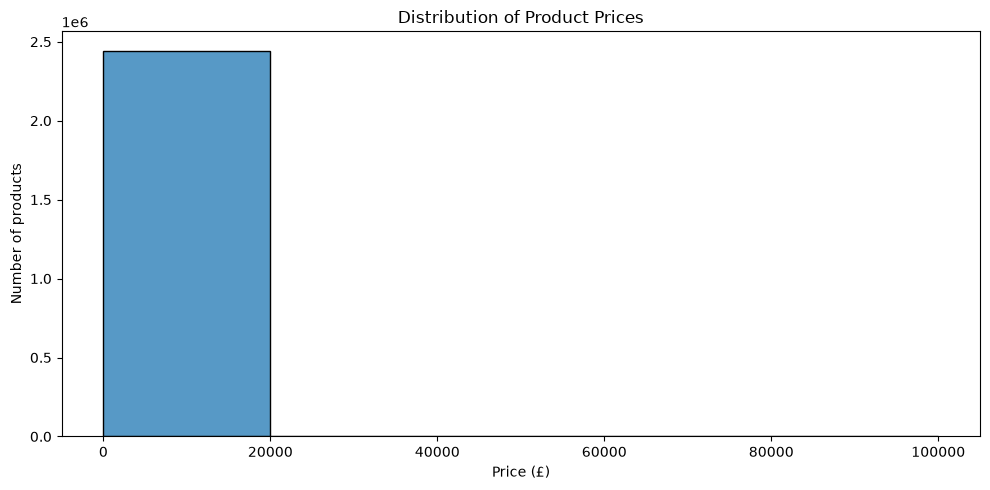

In [33]:
plt.figure(figsize=(10, 5))

sns.histplot(data=df, x="price", bins=5)

plt.title("Distribution of Product Prices")
plt.xlabel("Price (£)")
plt.ylabel("Number of products")
plt.tight_layout()
plt.show()

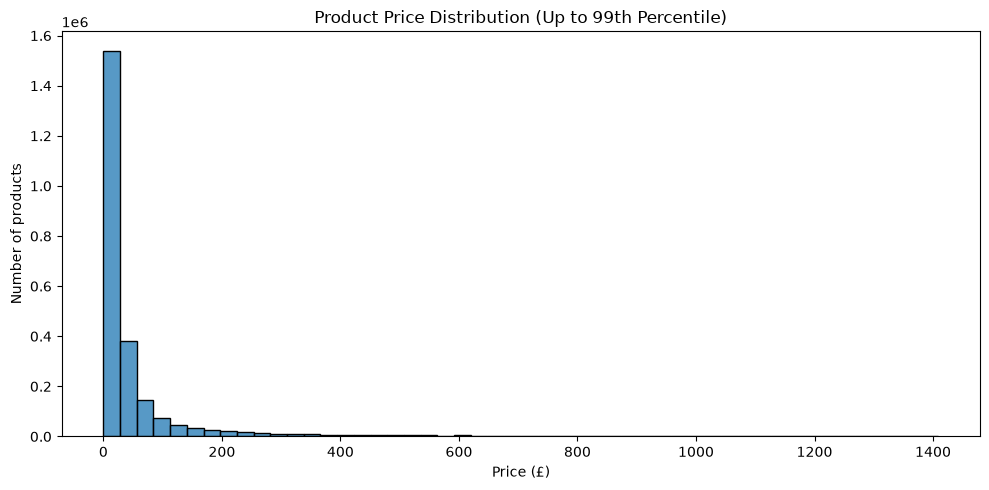

In [ ]:

price_99 = df["price"].quantile(0.99)

plt.figure(figsize=(10, 5))

sns.histplot(data=df[df["price"] <= price_99],x="price",bins=50)

plt.title("Product Price Distribution (Up to 99th Percentile)")
plt.xlabel("Price (£)")
plt.ylabel("Number of products")
plt.tight_layout()
plt.show()


La segunda gráfica excluye el 1 % de los productos más caros para facilitar la lectura; no debes eliminar esos registros del dataset original automáticamente.


2.4. Box plot de precios

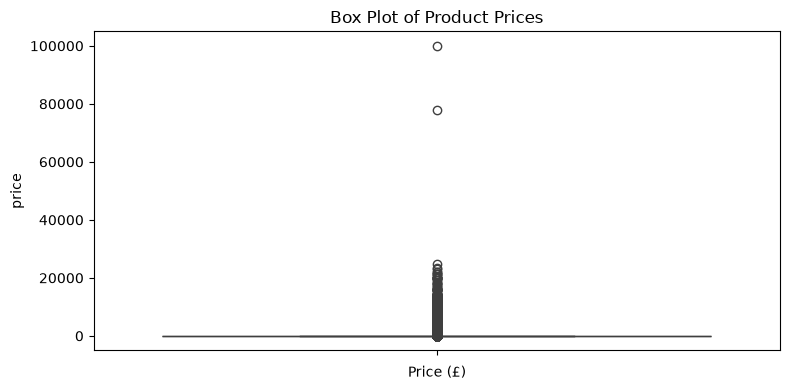

In [35]:

plt.figure(figsize=(8, 4))

sns.boxplot(y=df["price"])

plt.title("Box Plot of Product Prices")
plt.xlabel("Price (£)")
plt.tight_layout()
plt.show()

Esperamos observar numerosos valores atípicos en la parte superior, debido a la fuerte asimetría de los precios. El box plot utiliza el rango intercuartílico para identificar posibles valores atípicos; estos no son necesariamente errores, ya que pueden corresponder a productos legítimamente caros.

Part 3. Unpacking Product Ratings

En este dataset, la variable correspondiente a las valoraciones se llama stars. Antes de analizarla, conviene comprobar qué significan sus valores cero.

3.1. Medidas de tendencia central

In [36]:
# Comprobar la distribución de stars
print(df["stars"].value_counts().head(10))

# Medidas de centralidad
print("Mean:", df["stars"].mean())
print("Median:", df["stars"].median())
print("Mode:", df["stars"].mode().iloc[0])

stars
0.0    1225641
4.5     151577
4.6     136995
4.4     136165
5.0     128492
4.3     112564
4.7      94566
4.2      86871
4.0      66089
4.1      65115
Name: count, dtype: int64
Mean: 2.152836472966066
Median: 0.0
Mode: 0.0


Importante: en este dataset, el valor cero parece representar productos sin una valoración registrada, no necesariamente una valoración de cero estrellas. Por eso, estas estadísticas no describen correctamente la satisfacción de los clientes si se interpretan sin comprobar los ceros.
Para estudiar las valoraciones de productos que sí tienen estrellas registradas:

In [37]:
# Seleccionar productos con valoración positiva
rated_products = df[df["stars"] > 0]
ratings = rated_products["stars"]

print("Mean:", ratings.mean())
print("Median:", ratings.median())
print("Mode:", ratings.mode().tolist())

Mean: 4.319160762226911
Median: 4.4
Mode: [4.5]


Esta selección es útil para analizar las valoraciones registradas, aunque conviene verificar la definición de los datos antes de asumir que todos los ceros significan ausencia de reseñas.

3.2. Medidas de dispersión

In [38]:
print("Variance:", ratings.var())
print("Standard deviation:", ratings.std())
print("IQR:", ratings.quantile(0.75) - ratings.quantile(0.25))

Variance: 0.3083433752387284
Standard deviation: 0.5552867504620729
IQR: 0.5


Este código calcula la varianza, desviación estándar y rango intercuartílico utilizando exclusivamente los productos con estrellas positivas.
- Una desviación estándar pequeña indicaría que las valoraciones tienden a agruparse alrededor de la media.
- Una desviación estándar mayor indicaría una mayor variabilidad.
- El IQR describe la dispersión del 50 % central de las valoraciones registradas.

3.3. Asimetría y curtosis

In [27]:
print("Skewness:", ratings.skew())
print("Kurtosis:", ratings.kurt())

Skewness: -2.379568112212799
Kurtosis: 9.78193769066435


3.4. Histograma de valoraciones

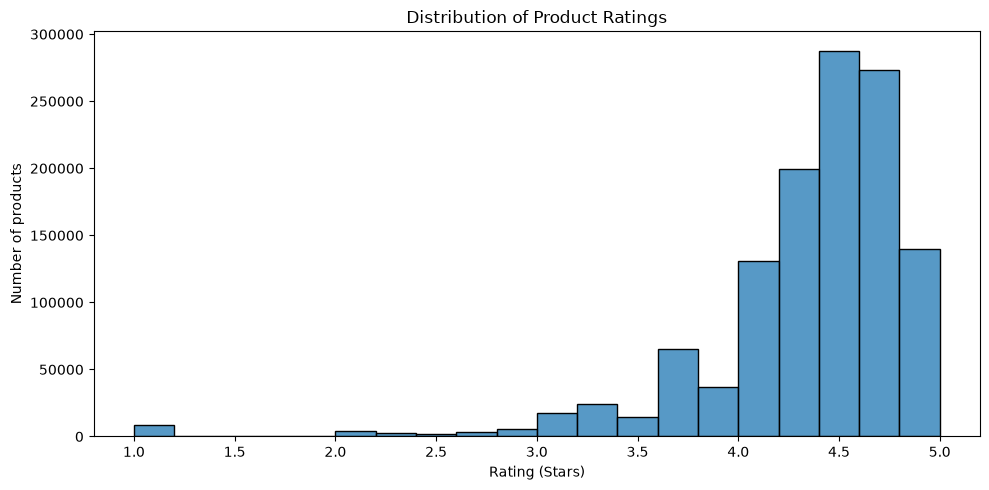

In [28]:
plt.figure(figsize=(10, 5))

sns.histplot(
    data=rated_products,
    x="stars",
    bins=20
)

plt.title("Distribution of Product Ratings")
plt.xlabel("Rating (Stars)")
plt.ylabel("Number of products")
plt.tight_layout()
plt.show()


Este gráfico permite comprobar si las valoraciones se concentran en valores altos, bajos o intermedios. Si observas una concentración alrededor de 4–5 estrellas, podrás concluir que predominan las valoraciones positivas entre los productos con estrellas registradas, sin asumir que todos los clientes están satisfechos.